# Load the dataset

In [1]:
import pandas as pd

file_path = "Caco2_Papp_20449_single_fragment_dataset.csv"

df_cs = pd.read_csv(file_path)

print("Dataset loaded successfully.")
print("Rows:", df_cs.shape[0])
print("Columns:", df_cs.shape[1])

print("\nColumns:")
print(df_cs.columns.tolist())

Dataset loaded successfully.
Rows: 20449
Columns: 15

Columns:
['canonical_smiles', 'n_measurements', 'n_assays', 'min_papp', 'max_papp', 'median_papp', 'mean_papp', 'log10_range', 'log10_median_papp', 'mean_median_ratio', 'mol', 'rdkit_canonical_smiles', 'n_fragments', 'parent_mol', 'parent_smiles']


# Check the dataset

In [2]:
print("\nMissing values:")
print(df_cs.isnull().sum())

print("\nFirst 5 rows:")
display(df_cs.head())


Missing values:
canonical_smiles          0
n_measurements            0
n_assays                  0
min_papp                  0
max_papp                  0
median_papp               0
mean_papp                 0
log10_range               0
log10_median_papp         0
mean_median_ratio         0
mol                       0
rdkit_canonical_smiles    0
n_fragments               0
parent_mol                0
parent_smiles             0
dtype: int64

First 5 rows:


,canonical_smiles,n_measurements,n_assays,min_papp,max_papp,median_papp,mean_papp,log10_range,log10_median_papp,mean_median_ratio,mol,rdkit_canonical_smiles,n_fragments,parent_mol,parent_smiles
0,Brc1ccc(-c2nc(-c3ccc4nc[nH]c4c3)no2)cc1,1,1,11.16,11.16,11.16,11.16,0.0,1.047664,1.0,<rdkit.Chem.rdchem.Mol object at 0x0000023E79B...,Brc1ccc(-c2nc(-c3ccc4nc[nH]c4c3)no2)cc1,1,<rdkit.Chem.rdchem.Mol object at 0x0000023E7B0...,Brc1ccc(-c2nc(-c3ccc4nc[nH]c4c3)no2)cc1
1,Brc1ccc(-c2nc3ccc(Br)cn3n2)cc1,1,1,3.49,3.49,3.49,3.49,0.0,0.542825,1.0,<rdkit.Chem.rdchem.Mol object at 0x0000023E79B...,Brc1ccc(-c2nc3ccc(Br)cn3n2)cc1,1,<rdkit.Chem.rdchem.Mol object at 0x0000023E7B0...,Brc1ccc(-c2nc3ccc(Br)cn3n2)cc1
2,Brc1ccc(-c2nnc(N3CCN(c4ccccn4)CC3)o2)cc1,1,1,5.90,5.90,5.90,5.90,0.0,0.770852,1.0,<rdkit.Chem.rdchem.Mol object at 0x0000023E79B...,Brc1ccc(-c2nnc(N3CCN(c4ccccn4)CC3)o2)cc1,1,<rdkit.Chem.rdchem.Mol object at 0x0000023E7B0...,Brc1ccc(-c2nnc(N3CCN(c4ccccn4)CC3)o2)cc1
3,Brc1ccc(C2(CC3CCCC3)c3ccccc3-c3nccn32)cn1,1,1,25.00,25.00,25.00,25.00,0.0,1.397940,1.0,<rdkit.Chem.rdchem.Mol object at 0x0000023E79B...,Brc1ccc(C2(CC3CCCC3)c3ccccc3-c3nccn32)cn1,1,<rdkit.Chem.rdchem.Mol object at 0x0000023E7B0...,Brc1ccc(C2(CC3CCCC3)c3ccccc3-c3nccn32)cn1
4,Brc1ccc(C2(CC3CCOCC3)c3ccccc3-c3nccn32)cc1,1,1,31.00,31.00,31.00,31.00,0.0,1.491362,1.0,<rdkit.Chem.rdchem.Mol object at 0x0000023E79B...,Brc1ccc(C2(CC3CCOCC3)c3ccccc3-c3nccn32)cc1,1,<rdkit.Chem.rdchem.Mol object at 0x0000023E7B0...,Brc1ccc(C2(CC3CCOCC3)c3ccccc3-c3nccn32)cc1


# verify RDKit molecule objects

In [3]:
from rdkit import Chem

print(type(df_cs["mol"].iloc[0]))
print("Invalid molecules:", df_cs["mol"].isna().sum())

<class 'str'>
Invalid molecules: 0


# Convert SMILES → RDKit Mol

In [4]:
from rdkit import Chem

df_cs["mol"] = df_cs["rdkit_canonical_smiles"].apply(
    lambda x: Chem.MolFromSmiles(x)
)

print(type(df_cs["mol"].iloc[0]))
print("Invalid molecules:", df_cs["mol"].isna().sum())

<class 'rdkit.Chem.rdchem.Mol'>
Invalid molecules: 0


# Generate Morgan fingerprints

In [5]:
from rdkit.Chem import rdFingerprintGenerator

morgan_gen = rdFingerprintGenerator.GetMorganGenerator(
    radius=2,
    fpSize=2048
)

df_cs["morgan_fp"] = df_cs["mol"].apply(
    lambda mol: morgan_gen.GetFingerprint(mol)
)

print("Morgan fingerprints generated.")
print("Number of molecules:", len(df_cs))
print("Fingerprint length:", len(df_cs["morgan_fp"].iloc[0]))

Morgan fingerprints generated.
Number of molecules: 20449
Fingerprint length: 2048


# Convert fingerprints into a matrix
We need this because the RDKit fingerprint objects are not yet a numerical matrix suitable for PCA/visualization or distance calculations.

In [7]:
from rdkit import DataStructs
import numpy as np
X_morgan = np.zeros(
    (len(df_cs), 2048),
    dtype=np.uint8
)

for i, fp in enumerate(df_cs["morgan_fp"]):
    DataStructs.ConvertToNumpyArray(fp, X_morgan[i])

print("Morgan matrix shape:", X_morgan.shape)
print("Data type:", X_morgan.dtype)

Morgan matrix shape: (20449, 2048)
Data type: uint8


- Molecules             : 20,449
- Morgan radius         : 2
- Fingerprint size      : 2,048 bits
- Matrix shape          : (20,449, 2,048)
- Data type             : uint8
- Invalid molecules     : 0

# Check fingerprint density
Before doing any chemical-space analysis, let's understand how many bits are typically active in each molecule.

In [9]:
active_bits = X_morgan.sum(axis=1)

print("=== Morgan Fingerprint Density ===")

print("Count:", len(active_bits))
print("Mean active bits:", active_bits.mean())
print("Median active bits:", np.median(active_bits))
print("Std:", active_bits.std())
print("Minimum active bits:", active_bits.min())
print("25th percentile:", np.percentile(active_bits, 25))
print("75th percentile:", np.percentile(active_bits, 75))
print("Maximum active bits:", active_bits.max())

=== Morgan Fingerprint Density ===
Count: 20449
Mean active bits: 57.10264560614211
Median active bits: 57.0
Std: 13.46805862779621
Minimum active bits: 8
25th percentile: 49.0
75th percentile: 64.0
Maximum active bits: 174


# Save the fingerprint representation

In [10]:
print("Morgan representation ready:")
print("Molecules:", X_morgan.shape[0])
print("Features:", X_morgan.shape[1])
print("Representation: Morgan fingerprint")
print("Radius: 2")

Morgan representation ready:
Molecules: 20449
Features: 2048
Representation: Morgan fingerprint
Radius: 2


# Tanimoto similarity
For Morgan fingerprints, we'll use Tanimoto similarity because it measures structural similarity between molecular fingerprints.
We will not calculate the full 20,449 × 20,449 similarity matrix. Instead, we'll first examine the nearest-neighbor similarity for each molecule.

In [11]:
from rdkit import DataStructs

# Calculate nearest-neighbor Tanimoto similarity
nearest_similarities = []

for i, fp in enumerate(df_cs["morgan_fp"]):
    similarities = DataStructs.BulkTanimotoSimilarity(
        fp,
        df_cs["morgan_fp"].tolist()
    )
    
    # Exclude self-similarity (which is 1.0)
    similarities[i] = -1
    
    nearest_similarities.append(max(similarities))

nearest_similarities = np.array(nearest_similarities)

print("=== Nearest-Neighbor Tanimoto Similarity ===")
print("Mean:", nearest_similarities.mean())
print("Median:", np.median(nearest_similarities))
print("Minimum:", nearest_similarities.min())
print("25th percentile:", np.percentile(nearest_similarities, 25))
print("75th percentile:", np.percentile(nearest_similarities, 75))
print("Maximum:", nearest_similarities.max())

=== Nearest-Neighbor Tanimoto Similarity ===
Mean: 0.7624320044676847
Median: 0.7910447761194029
Minimum: 0.16666666666666666
25th percentile: 0.703125
75th percentile: 0.8522727272727273
Maximum: 1.0


# Interpretation
- Most molecules have a relatively similar structural neighbor:
 
- Median = 0.791 → half of the molecules have a nearest neighbor with similarity ≥ 0.791.

- 75% = 0.852 → many molecules have quite close structural neighbors.
 
- Minimum = 0.167 → some molecules are structurally isolated from the rest of the dataset.
  
- Maximum = 1.0 → at least some molecules have an identical fingerprint to another molecule.

# how many molecules have nearest-neighbor similarity = 1.0.

In [12]:
print("Molecules with nearest-neighbor similarity = 1.0:",
      np.sum(nearest_similarities == 1.0))

print("Percentage:",
      np.mean(nearest_similarities == 1.0) * 100)

Molecules with nearest-neighbor similarity = 1.0: 1254
Percentage: 6.132329209252286


In [13]:
print("Duplicate RDKit canonical SMILES:",
      df_cs["rdkit_canonical_smiles"].duplicated().sum())

Duplicate RDKit canonical SMILES: 0


# check the parent structure

In [14]:
print("Duplicate parent SMILES:",
      df_cs["parent_smiles"].duplicated().sum())

Duplicate parent SMILES: 0


# let's identify the molecules whose nearest-neighbor similarity is exactly 1.0:

In [15]:
identical_nn = np.where(nearest_similarities == 1.0)[0]

print("Number of molecules:", len(identical_nn))

print("\nFirst 10 cases:")
display(
    df_cs.iloc[identical_nn[:10]][
        ["canonical_smiles",
         "rdkit_canonical_smiles",
         "parent_smiles",
         "n_measurements",
         "log10_median_papp"]
    ]
)

Number of molecules: 1254

First 10 cases:


,canonical_smiles,rdkit_canonical_smiles,parent_smiles,n_measurements,log10_median_papp
21,C#CCN(C)CCCCCCCCOc1ccc2c(c1)OCCC2=O,C#CCN(C)CCCCCCCCOc1ccc2c(c1)OCCC2=O,C#CCN(C)CCCCCCCCOc1ccc2c(c1)OCCC2=O,1,0.949878
23,C#CCN(C)CCCCCCOc1ccc(C=O)c(OC)c1,C#CCN(C)CCCCCCOc1ccc(C=O)c(OC)c1,C#CCN(C)CCCCCCOc1ccc(C=O)c(OC)c1,1,1.048442
24,C#CCN(C)CCCCCCOc1ccc2c(c1)CCC2=O,C#CCN(C)CCCCCCOc1ccc2c(c1)CCC2=O,C#CCN(C)CCCCCCOc1ccc2c(c1)CCC2=O,1,1.108903
25,C#CCN(C)CCCCCCOc1ccc2c(c1)CCCC2=O,C#CCN(C)CCCCCCOc1ccc2c(c1)CCCC2=O,C#CCN(C)CCCCCCOc1ccc2c(c1)CCCC2=O,1,0.933487
27,C#CCN(C)CCCCCCOc1ccc2c(c1)OCCC2=O,C#CCN(C)CCCCCCOc1ccc2c(c1)OCCC2=O,C#CCN(C)CCCCCCOc1ccc2c(c1)OCCC2=O,1,0.931458
29,C#CCN(C)CCCCCOc1ccc(C=O)c(OC)c1,C#CCN(C)CCCCCOc1ccc(C=O)c(OC)c1,C#CCN(C)CCCCCOc1ccc(C=O)c(OC)c1,1,1.147367
30,C#CCN(C)CCCCCOc1ccc2c(c1)CCC2=O,C#CCN(C)CCCCCOc1ccc2c(c1)CCC2=O,C#CCN(C)CCCCCOc1ccc2c(c1)CCC2=O,1,1.037825
31,C#CCN(C)CCCCCOc1ccc2c(c1)CCCC2=O,C#CCN(C)CCCCCOc1ccc2c(c1)CCCC2=O,C#CCN(C)CCCCCOc1ccc2c(c1)CCCC2=O,1,1.026533
32,C#CCN(C)CCCCCOc1ccc2c(c1)OCCC2=O,C#CCN(C)CCCCCOc1ccc2c(c1)OCCC2=O,C#CCN(C)CCCCCOc1ccc2c(c1)OCCC2=O,1,1.010724
168,C/C(CN(C[C@H]1Cc2ccccc2CN1)[C@H]1CCCc2cccnc21)...,C/C(CN(C[C@H]1Cc2ccccc2CN1)[C@H]1CCCc2cccnc21)...,C/C(CN(C[C@H]1Cc2ccccc2CN1)[C@H]1CCCc2cccnc21)...,1,1.845098


- Let's determine whether these 1,254 molecules actually have different structures but identical fingerprints.

- We can directly compare their canonical SMILES against their nearest neighbor.

- However, our current nearest_similarities array only stores the similarity, not the identity of the nearest neighbor. So let's modify the calculation to store the nearest-neighbor index as well.

In [16]:
nearest_indices = []
nearest_similarities_2 = []

fps = df_cs["morgan_fp"].tolist()

for i, fp in enumerate(fps):
    similarities = np.array(
        DataStructs.BulkTanimotoSimilarity(fp, fps)
    )
    
    similarities[i] = -1
    
    nn_idx = np.argmax(similarities)
    
    nearest_indices.append(nn_idx)
    nearest_similarities_2.append(similarities[nn_idx])

nearest_indices = np.array(nearest_indices)
nearest_similarities_2 = np.array(nearest_similarities_2)

print("Nearest-neighbor calculation completed.")
print("Mean similarity:", nearest_similarities_2.mean())

Nearest-neighbor calculation completed.
Mean similarity: 0.7624320044676847


In [17]:
identical_fp_idx = np.where(nearest_similarities_2 == 1.0)[0]

same_structure = (
    df_cs.iloc[identical_fp_idx]["rdkit_canonical_smiles"].values
    ==
    df_cs.iloc[nearest_indices[identical_fp_idx]]["rdkit_canonical_smiles"].values
)

print("Fingerprint-identical molecules:", len(identical_fp_idx))
print("Structurally identical:", same_structure.sum())
print("Structurally different:", (~same_structure).sum())

Fingerprint-identical molecules: 1254
Structurally identical: 0
Structurally different: 1254


-  So all 1,254 molecules (6.13%) have a Morgan fingerprint identical to another molecule, while their canonical SMILES are different.

    
What this means
    
- These are Morgan fingerprint collisions.
    
- The fingerprint is a hashed 2048-bit representation. Different molecular structures can therefore map to the same fingerprint.

So:

- Tanimoto similarity = 1.0 does NOT necessarily mean structural identity in our dataset.
This is particularly important for our study because we are investigating how molecular representation influences chemical-space distance.

"A subset of structurally distinct molecules produced identical 2048-bit Morgan fingerprints, indicating representation-level collisions. These molecules were retained to avoid introducing representation-dependent selection bias."

In [19]:
nearest_distances = 1 - nearest_similarities_2

print("=== Nearest-Neighbor Tanimoto Distance ===")
print("Mean:", nearest_distances.mean())
print("Median:", np.median(nearest_distances))
print("Minimum:", nearest_distances.min())
print("25th percentile:", np.percentile(nearest_distances, 25))
print("75th percentile:", np.percentile(nearest_distances, 75))
print("Maximum:", nearest_distances.max())

=== Nearest-Neighbor Tanimoto Distance ===
Mean: 0.23756799553231536
Median: 0.20895522388059706
Minimum: 0.0
25th percentile: 0.1477272727272727
75th percentile: 0.296875
Maximum: 0.8333333333333334


# let's visualize the distribution of nearest-neighbor distance.

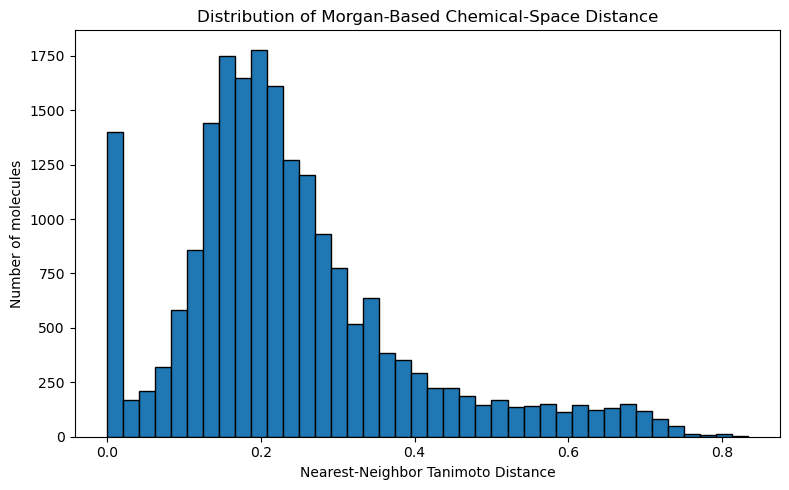

In [20]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.hist(
    nearest_distances,
    bins=40,
    edgecolor="black"
)

plt.xlabel("Nearest-Neighbor Tanimoto Distance")
plt.ylabel("Number of molecules")
plt.title("Distribution of Morgan-Based Chemical-Space Distance")

plt.tight_layout()
plt.show()

- From the plot:

- There is a clear spike at distance = 0, corresponding to the 1,254 fingerprint-identical cases we already identified.
- Most molecules fall roughly in the 0.1–0.35 distance range.
= The distribution has a right-hand tail extending to ~0.83, representing increasingly isolated molecules.

    This is consistent with our summary statistics:
- Mean = 0.238
- Median = 0.209
- 75th percentile = 0.297
- Maximum = 0.833

In [22]:
import pickle

morgan_data = {
    "df_cs": df_cs,
    "X_morgan": X_morgan,
    "nearest_indices": nearest_indices,
    "nearest_similarities": nearest_similarities_2,
    "nearest_distances": nearest_distances
}

with open("caco2_morgan_chemical_space.pkl", "wb") as f:
    pickle.dump(morgan_data, f)

print("Morgan chemical-space dataset saved successfully.")

Morgan chemical-space dataset saved successfully.


# Representation 2 — RDKit molecular descriptors

# Step 1 — Generate RDKit descriptors

In [23]:
from rdkit.Chem import Descriptors
import numpy as np
import pandas as pd

# List of RDKit molecular descriptors
descriptor_functions = [
    (name, func)
    for name, func in Descriptors.descList
]

print("Number of descriptors:", len(descriptor_functions))

Number of descriptors: 217


# Generate descriptor Matrix

In [24]:
descriptor_data = []

for mol in df_cs["mol"]:
    values = []

    for name, func in descriptor_functions:
        try:
            values.append(func(mol))
        except Exception:
            values.append(np.nan)

    descriptor_data.append(values)

X_rdkit = np.array(descriptor_data, dtype=float)

print("RDKit descriptor matrix shape:", X_rdkit.shape)
print("Data type:", X_rdkit.dtype)

RDKit descriptor matrix shape: (20449, 217)
Data type: float64


# Step 2 — Check the descriptors

In [25]:
print("=== RDKit Descriptor Quality Check ===")

print("Molecules:", X_rdkit.shape[0])
print("Descriptors:", X_rdkit.shape[1])
print("NaN values:", np.isnan(X_rdkit).sum())
print("Infinite values:", np.isinf(X_rdkit).sum())

=== RDKit Descriptor Quality Check ===
Molecules: 20449
Descriptors: 217
NaN values: 132
Infinite values: 0


In [26]:
descriptor_names = [name for name, func in descriptor_functions]

print("\nFirst 10 descriptors:")
print(descriptor_names[:10])


First 10 descriptors:
['MaxAbsEStateIndex', 'MaxEStateIndex', 'MinAbsEStateIndex', 'MinEStateIndex', 'qed', 'SPS', 'MolWt', 'HeavyAtomMolWt', 'ExactMolWt', 'NumValenceElectrons']


# identify where the NaNs occur

In [27]:
nan_counts = pd.Series(
    np.isnan(X_rdkit).sum(axis=0),
    index=descriptor_names
)

nan_counts = nan_counts[nan_counts > 0].sort_values(ascending=False)

print("Descriptors containing NaN values:")
print(nan_counts)

Descriptors containing NaN values:
MaxPartialCharge       11
MinPartialCharge       11
MaxAbsPartialCharge    11
MinAbsPartialCharge    11
BCUT2D_MWHI            11
BCUT2D_MWLOW           11
BCUT2D_CHGHI           11
BCUT2D_CHGLO           11
BCUT2D_LOGPHI          11
BCUT2D_LOGPLOW         11
BCUT2D_MRHI            11
BCUT2D_MRLOW           11
dtype: int32


In [28]:
nan_per_molecule = np.isnan(X_rdkit).sum(axis=1)

print("Molecules containing at least one NaN:",
      np.sum(nan_per_molecule > 0))

print("Maximum NaNs in a single molecule:",
      nan_per_molecule.max())

Molecules containing at least one NaN: 11
Maximum NaNs in a single molecule: 12


In [29]:
rdkit_valid_descriptors = [
    name for name in descriptor_names
    if name not in nan_counts.index
]

print("Original descriptors:", len(descriptor_names))
print("Removed descriptors:", len(nan_counts))
print("Final descriptors:", len(rdkit_valid_descriptors))

print("\nRemoved descriptors:")
print(list(nan_counts.index))

Original descriptors: 217
Removed descriptors: 12
Final descriptors: 205

Removed descriptors:
['MaxPartialCharge', 'MinPartialCharge', 'MaxAbsPartialCharge', 'MinAbsPartialCharge', 'BCUT2D_MWHI', 'BCUT2D_MWLOW', 'BCUT2D_CHGHI', 'BCUT2D_CHGLO', 'BCUT2D_LOGPHI', 'BCUT2D_LOGPLOW', 'BCUT2D_MRHI', 'BCUT2D_MRLOW']


# create the cleaned RDKit matrix

In [30]:
valid_indices = [
    i for i, name in enumerate(descriptor_names)
    if name not in nan_counts.index
]

X_rdkit_clean = X_rdkit[:, valid_indices]

print("Clean RDKit descriptor matrix:")
print("Shape:", X_rdkit_clean.shape)
print("NaN values:", np.isnan(X_rdkit_clean).sum())
print("Infinite values:", np.isinf(X_rdkit_clean).sum())

Clean RDKit descriptor matrix:
Shape: (20449, 205)
NaN values: 0
Infinite values: 0


# Descriptor scaling

- Before calculating chemical-space distances, we need to address an important issue: the 205 descriptors are on very different numerical scales.
    
For example:
- Molecular weight → hundreds
- TPSA → tens/hundreds
- HBD/HBA → small integers
- E-state descriptors → different ranges
    
If we calculate Euclidean distance directly, large-scale descriptors could dominate the distance.
    
So the next step is to standardize each descriptor.

In [31]:
from sklearn.preprocessing import StandardScaler

scaler_rdkit = StandardScaler()

X_rdkit_scaled = scaler_rdkit.fit_transform(X_rdkit_clean)

print("Scaled RDKit descriptor matrix:")
print("Shape:", X_rdkit_scaled.shape)
print("Mean:", np.mean(X_rdkit_scaled))
print("Std:", np.std(X_rdkit_scaled))

Scaled RDKit descriptor matrix:
Shape: (20449, 205)
Mean: -9.315603424432492e-18
Std: 0.9802936344565834


# RDKit chemical-space distance

Euclidean nearest-neighbor distance in the standardized 205-dimensional RDKit descriptor space.
Because 20,449 × 20,449 comparisons would be expensive, use NearestNeighbors rather than a full distance matrix:

In [32]:
from sklearn.neighbors import NearestNeighbors

nn_rdkit = NearestNeighbors(
    n_neighbors=2,
    metric="euclidean",
    n_jobs=-1
)

nn_rdkit.fit(X_rdkit_scaled)

distances_rdkit, indices_rdkit = nn_rdkit.kneighbors(X_rdkit_scaled)

# First neighbor is the molecule itself
nearest_rdkit_distance = distances_rdkit[:, 1]

nearest_rdkit_index = indices_rdkit[:, 1]

print("=== RDKit Nearest-Neighbor Distance ===")
print("Mean:", nearest_rdkit_distance.mean())
print("Median:", np.median(nearest_rdkit_distance))
print("Minimum:", nearest_rdkit_distance.min())
print("25th percentile:", np.percentile(nearest_rdkit_distance, 25))
print("75th percentile:", np.percentile(nearest_rdkit_distance, 75))
print("Maximum:", nearest_rdkit_distance.max())

=== RDKit Nearest-Neighbor Distance ===
Mean: 3.793284243736487
Median: 3.4246974291796164
Minimum: 0.0
25th percentile: 1.957536114051688
75th percentile: 5.249612985687371
Maximum: 143.37995235042425


# Inspect the RDKit distance distribution

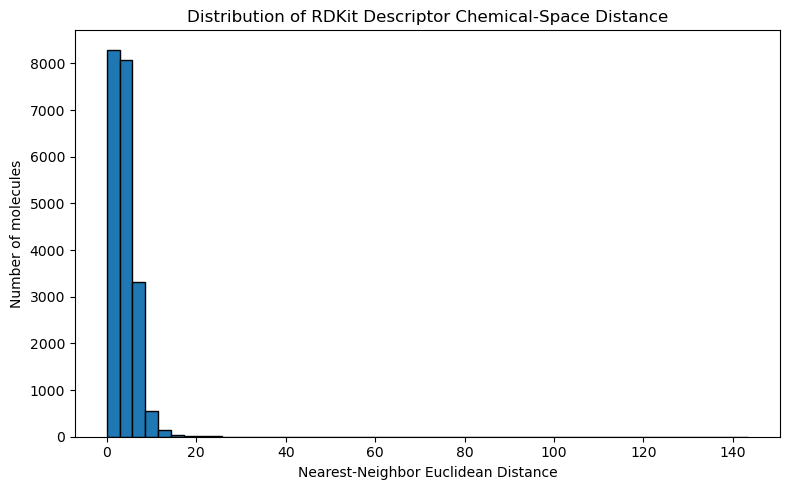

In [33]:
plt.figure(figsize=(8, 5))

plt.hist(
    nearest_rdkit_distance,
    bins=50,
    edgecolor="black"
)

plt.xlabel("Nearest-Neighbor Euclidean Distance")
plt.ylabel("Number of molecules")
plt.title("Distribution of RDKit Descriptor Chemical-Space Distance")

plt.tight_layout()
plt.show()

In [36]:
# Compare Morgan and RDKit chemical-space distances

comparison = pd.DataFrame({
    "Morgan_Tanimoto_Distance": nearest_distances,
    "RDKit_Euclidean_Distance": nearest_rdkit_distance
})

print("=== Correlation Between Chemical-Space Representations ===")
print(comparison.corr(method="spearman"))

=== Correlation Between Chemical-Space Representations ===
                          Morgan_Tanimoto_Distance  RDKit_Euclidean_Distance
Morgan_Tanimoto_Distance                  1.000000                  0.592106
RDKit_Euclidean_Distance                  0.592106                  1.000000


In [37]:
print("Morgan distances:", len(nearest_distances))
print("RDKit distances:", len(nearest_rdkit_distance))

Morgan distances: 20449
RDKit distances: 20449


In [41]:
import pickle

# Create final descriptor names
final_descriptor_names = [
    name for name in descriptor_names
    if name not in nan_counts.index
]

rdkit_chemical_space = {
    "molecules": df_cs["rdkit_canonical_smiles"].values,
    "descriptors": X_rdkit_clean,
    "descriptors_scaled": X_rdkit_scaled,
    "descriptor_names": final_descriptor_names,
    "nearest_neighbor_distance": nearest_rdkit_distance
}

with open("RDKit_descriptor_chemical_space.pkl", "wb") as f:
    pickle.dump(rdkit_chemical_space, f)

print("RDKit descriptor chemical-space dataset saved successfully.")

RDKit descriptor chemical-space dataset saved successfully.


In [42]:
print("Molecules:", len(rdkit_chemical_space["molecules"]))
print("Descriptors:", len(rdkit_chemical_space["descriptor_names"]))
print("Scaled matrix:", rdkit_chemical_space["descriptors_scaled"].shape)

Molecules: 20449
Descriptors: 205
Scaled matrix: (20449, 205)


# Representation 3 — Hybrid chemical-space representation
The purpose of the hybrid representation is to combine:

Morgan fingerprints → structural/substructural information

RDKit descriptors → physicochemical and topological information

# Step 1 — Combine the two representations

In [43]:
# Combine Morgan fingerprints and scaled RDKit descriptors

X_hybrid = np.hstack([
    X_morgan.astype(float),
    X_rdkit_scaled
])

print("=== Hybrid Representation ===")
print("Molecules:", X_hybrid.shape[0])
print("Total features:", X_hybrid.shape[1])
print("Morgan features:", X_morgan.shape[1])
print("RDKit features:", X_rdkit_scaled.shape[1])

=== Hybrid Representation ===
Molecules: 20449
Total features: 2253
Morgan features: 2048
RDKit features: 205


# Hybrid chemical-space distance.
Because the hybrid contains both binary fingerprint features and continuous standardized descriptors, we need to be careful about the distance metric. We shouldn't simply assume Euclidean distance is appropriate.

# Next step — check the contribution of each component

In [44]:
morgan_norm = np.linalg.norm(X_morgan.astype(float), axis=1)
rdkit_norm = np.linalg.norm(X_rdkit_scaled, axis=1)

print("=== Representation Magnitudes ===")

print("\nMorgan:")
print("Mean L2 norm:", morgan_norm.mean())
print("Median L2 norm:", np.median(morgan_norm))

print("\nRDKit:")
print("Mean L2 norm:", rdkit_norm.mean())
print("Median L2 norm:", np.median(rdkit_norm))

=== Representation Magnitudes ===

Morgan:
Mean L2 norm: 7.503643871911128
Median L2 norm: 7.54983443527075

RDKit:
Mean L2 norm: 12.259366830791764
Median L2 norm: 10.914353303511938


# Step 2 — Normalize each representation as a whole
We'll normalize each molecule's Morgan vector and RDKit vector to unit length, then concatenate them. This prevents one representation from dominating simply because of its numerical magnitude.

In [45]:
from sklearn.preprocessing import normalize

# Normalize each representation independently
X_morgan_norm = normalize(
    X_morgan.astype(float),
    norm="l2"
)

X_rdkit_norm = normalize(
    X_rdkit_scaled,
    norm="l2"
)

# Combine normalized representations
X_hybrid_balanced = np.hstack([
    X_morgan_norm,
    X_rdkit_norm
])

print("=== Balanced Hybrid Representation ===")
print("Shape:", X_hybrid_balanced.shape)
print("Morgan shape:", X_morgan_norm.shape)
print("RDKit shape:", X_rdkit_norm.shape)

=== Balanced Hybrid Representation ===
Shape: (20449, 2253)
Morgan shape: (20449, 2048)
RDKit shape: (20449, 205)


# Verify the balance

In [46]:
print("=== Component Norms After Normalization ===")

print("Morgan mean norm:",
      np.linalg.norm(X_morgan_norm, axis=1).mean())

print("RDKit mean norm:",
      np.linalg.norm(X_rdkit_norm, axis=1).mean())

=== Component Norms After Normalization ===
Morgan mean norm: 1.0
RDKit mean norm: 1.0


# Calculate hybrid nearest-neighbor distance

In [47]:
from sklearn.neighbors import NearestNeighbors

nn_hybrid = NearestNeighbors(
    n_neighbors=2,
    metric="euclidean",
    n_jobs=-1
)

nn_hybrid.fit(X_hybrid_balanced)

distances_hybrid, indices_hybrid = nn_hybrid.kneighbors(
    X_hybrid_balanced
)

# First neighbor is the molecule itself
nearest_hybrid_distance = distances_hybrid[:, 1]
nearest_hybrid_index = indices_hybrid[:, 1]

print("=== Hybrid Nearest-Neighbor Distance ===")
print("Mean:", nearest_hybrid_distance.mean())
print("Median:", np.median(nearest_hybrid_distance))
print("Minimum:", nearest_hybrid_distance.min())
print("25th percentile:", np.percentile(nearest_hybrid_distance, 25))
print("75th percentile:", np.percentile(nearest_hybrid_distance, 75))
print("Maximum:", nearest_hybrid_distance.max())

=== Hybrid Nearest-Neighbor Distance ===
Mean: 0.6372817578271975
Median: 0.6093110569869126
Minimum: 0.0
25th percentile: 0.490796414218901
75th percentile: 0.771477857886506
Maximum: 1.8042315634142057


# save the hybrid representation and its nearest-neighbor results.

In [48]:
import pickle

hybrid_chemical_space = {
    "molecules": df_cs["rdkit_canonical_smiles"].values,
    "morgan_normalized": X_morgan_norm,
    "rdkit_normalized": X_rdkit_norm,
    "hybrid_representation": X_hybrid_balanced,
    "nearest_neighbor_distance": nearest_hybrid_distance,
    "nearest_neighbor_index": nearest_hybrid_index
}

with open("Hybrid_chemical_space.pkl", "wb") as f:
    pickle.dump(hybrid_chemical_space, f)

print("Hybrid chemical-space dataset saved successfully.")

Hybrid chemical-space dataset saved successfully.


In [49]:
print("Molecules:", len(hybrid_chemical_space["molecules"]))
print("Hybrid shape:", hybrid_chemical_space["hybrid_representation"].shape)
print("Distance values:", len(hybrid_chemical_space["nearest_neighbor_distance"]))

Molecules: 20449
Hybrid shape: (20449, 2253)
Distance values: 20449


# Create the master chemical-space table

In [50]:
chemical_space_master = pd.DataFrame({
    "canonical_smiles": df_cs["canonical_smiles"].values,
    "log10_median_papp": df_cs["log10_median_papp"].values,
    "Morgan_distance": nearest_distances,
    "RDKit_distance": nearest_rdkit_distance,
    "Hybrid_distance": nearest_hybrid_distance
})

print("=== Chemical-Space Master Table ===")
print("Rows:", len(chemical_space_master))
print("Columns:", chemical_space_master.shape[1])

print("\nColumns:")
print(chemical_space_master.columns.tolist())

print("\nMissing values:")
print(chemical_space_master.isna().sum())

=== Chemical-Space Master Table ===
Rows: 20449
Columns: 5

Columns:
['canonical_smiles', 'log10_median_papp', 'Morgan_distance', 'RDKit_distance', 'Hybrid_distance']

Missing values:
canonical_smiles     0
log10_median_papp    0
Morgan_distance      0
RDKit_distance       0
Hybrid_distance      0
dtype: int64


In [51]:
chemical_space_master.head()

,canonical_smiles,log10_median_papp,Morgan_distance,RDKit_distance,Hybrid_distance
0,Brc1ccc(-c2nc(-c3ccc4nc[nH]c4c3)no2)cc1,1.047664,0.200000,2.864551,0.539836
1,Brc1ccc(-c2nc3ccc(Br)cn3n2)cc1,0.542825,0.575000,6.721927,1.051168
2,Brc1ccc(-c2nnc(N3CCN(c4ccccn4)CC3)o2)cc1,0.770852,0.276596,6.929545,1.041043
3,Brc1ccc(C2(CC3CCCC3)c3ccccc3-c3nccn32)cn1,1.397940,0.321429,5.158925,0.798420
4,Brc1ccc(C2(CC3CCOCC3)c3ccccc3-c3nccn32)cc1,1.491362,0.188679,2.751963,0.535231


In [52]:
chemical_space_master.describe()

,log10_median_papp,Morgan_distance,RDKit_distance,Hybrid_distance
count,20449.000000,20449.000000,20449.000000,20449.000000
mean,0.852952,0.237568,3.793284,0.637282
std,0.820542,0.150900,2.945914,0.280907
min,-4.000000,0.000000,0.000000,0.000000
25%,0.380211,0.147727,1.957536,0.490796
50%,0.982271,0.208955,3.424697,0.609311
75%,1.361728,0.296875,5.249613,0.771478
max,4.444661,0.833333,143.379952,1.804232


In [53]:
chemical_space_master.to_pickle(
    "Caco2_chemical_space_master.pkl"
)

print("Chemical-space master table saved successfully.")

Chemical-space master table saved successfully.


# 05 — Chemical-Space Representation

## 1. Objective

This analysis was designed to characterize the chemical space of the Caco-2 permeability dataset using multiple molecular representations and to quantify the local chemical-space environment surrounding each molecule.

The primary objective was to determine whether different molecular representations describe chemical-space relationships differently. Three representations were evaluated:

1. Morgan molecular fingerprints
2. RDKit molecular descriptors
3. Hybrid representation combining Morgan fingerprints and RDKit descriptors

For each representation, a nearest-neighbor chemical-space distance was calculated for every molecule.

These representation-specific distances were subsequently assembled into a master chemical-space table for integration with prediction-error analysis.

The overall research framework is:

Molecular structure → Molecular representation → Chemical-space distance → Prediction error

The prediction-error analysis is performed separately from this notebook.

---

# 2. Dataset

The dataset consisted of experimentally measured Caco-2 permeability values summarized at the molecular level.

After dataset preparation, the final dataset contained:

- 20,449 unique molecular records
- 15 original dataset columns
- No missing values in the retained dataset

The principal permeability response used in the chemical-space analysis was:

log10_median_papp

The dataset contained the following relevant variables:

- canonical_smiles
- n_measurements
- n_assays
- min_papp
- max_papp
- median_papp
- mean_papp
- log10_range
- log10_median_papp
- mean_median_ratio
- mol
- rdkit_canonical_smiles
- n_fragments
- parent_mol
- parent_smiles

No missing values were detected in the final dataset.

---

# 3. Molecular Validity Check

The molecular structures were represented using RDKit molecular objects.

All 20,449 molecules were successfully converted into valid RDKit molecular representations.

The final molecular validity check showed:

- Invalid molecules: 0
- Valid molecules: 20,449

Therefore, no molecules were removed because of invalid molecular structures during the representation stage.

---

# 4. Representation I — Morgan Fingerprints

## 4.1 Morgan fingerprint generation

Molecular structures were converted into circular Morgan fingerprints using:

- Radius: 2
- Fingerprint length: 2048 bits

The resulting Morgan fingerprint matrix had dimensions:

20,449 × 2,048

The fingerprint matrix was stored as an unsigned 8-bit integer matrix (uint8).

Morgan fingerprints were selected to capture local molecular structural patterns and substructural environments.

---

## 4.2 Morgan fingerprint density

The number of active fingerprint bits was calculated for each molecule to characterize fingerprint density.

The distribution was:

| Statistic | Active bits |
|---|---:|
| Number of molecules | 20,449 |
| Mean | 57.10 |
| Median | 57.0 |
| Standard deviation | 13.47 |
| Minimum | 8 |
| 25th percentile | 49.0 |
| 75th percentile | 64.0 |
| Maximum | 174 |

Thus, although the fingerprint representation contained 2,048 possible dimensions, individual molecules activated a relatively small subset of these structural features.

---

# 5. Morgan-Based Chemical-Space Distance

Chemical similarity between molecules was quantified using the Tanimoto similarity between Morgan fingerprints.

For each molecule, the nearest molecular neighbor was identified.

Chemical-space distance was defined as:

Tanimoto distance = 1 − Tanimoto similarity

The nearest-neighbor Tanimoto similarity distribution showed:

| Statistic | Nearest-neighbor similarity |
|---|---:|
| Mean | 0.7624 |
| Median | 0.7910 |
| Minimum | 0.1667 |
| 25th percentile | 0.7031 |
| 75th percentile | 0.8523 |
| Maximum | 1.0000 |

The corresponding nearest-neighbor Tanimoto distance distribution was:

| Statistic | Morgan distance |
|---|---:|
| Mean | 0.2376 |
| Median | 0.2090 |
| Minimum | 0.0000 |
| 25th percentile | 0.1477 |
| 75th percentile | 0.2969 |
| Maximum | 0.8333 |

The distribution indicates that most molecules have relatively close structural neighbors in Morgan fingerprint space, while a smaller fraction occupy more isolated regions of the fingerprint-defined chemical space.

---

# 6. Fingerprint-Identical Molecule Quality Check

A nearest-neighbor Tanimoto similarity of 1.0 was observed for:

1,254 molecules

This corresponds to:

6.13% of the dataset.

A structural comparison was subsequently performed.

The analysis identified:

- Fingerprint-identical molecules: 1,254
- Structurally identical: 0
- Structurally different: 1,254

Therefore, the molecules sharing identical Morgan fingerprint vectors were not identical according to the structural representation used in the subsequent comparison.

This observation is important because it demonstrates that a fingerprint representation can map chemically distinct molecular structures to the same binary representation. Such cases represent a limitation of the finite fingerprint representation rather than direct evidence of molecular identity.

These observations were retained rather than automatically removing the molecules, because the purpose of the study is specifically to examine how molecular representation influences chemical-space relationships.

---

# 7. Representation II — RDKit Molecular Descriptors

A second molecular representation was generated using RDKit molecular descriptors.

The initial descriptor matrix contained:

20,449 molecules × 217 descriptors

The descriptors included physicochemical, topological, electronic-state, and molecular-property-related quantities generated from the RDKit descriptor framework.

Examples of the initial descriptors included:

- MaxAbsEStateIndex
- MaxEStateIndex
- MinAbsEStateIndex
- MinEStateIndex
- qed
- SPS
- MolWt
- HeavyAtomMolWt
- ExactMolWt
- NumValenceElectrons

---

# 8. RDKit Descriptor Quality Control

The initial descriptor matrix contained:

- 132 total NaN values
- 0 infinite values
- 11 molecules containing at least one NaN
- Maximum number of NaNs in a single molecule: 12

The NaN-containing descriptors were:

- MaxPartialCharge
- MinPartialCharge
- MaxAbsPartialCharge
- MinAbsPartialCharge
- BCUT2D_MWHI
- BCUT2D_MWLOW
- BCUT2D_CHGHI
- BCUT2D_CHGLO
- BCUT2D_LOGPHI
- BCUT2D_LOGPLOW
- BCUT2D_MRHI
- BCUT2D_MRLOW

These 12 descriptors were removed from the representation because they contained undefined values for a subset of molecules.

The final descriptor representation therefore contained:

- Original descriptors: 217
- Removed descriptors: 12
- Final descriptors: 205

After removal:

- NaN values: 0
- Infinite values: 0
- Final matrix: 20,449 × 205

---

# 9. Scaling of RDKit Descriptors

The 205 retained RDKit descriptors were standardized prior to Euclidean distance calculation.

The resulting scaled descriptor matrix had dimensions:

20,449 × 205

The mean of the complete scaled matrix was approximately zero:

Mean = −9.32 × 10⁻¹⁸

The overall standard deviation was approximately:

0.98

Standardization was performed so that descriptors with different original numerical scales would not dominate the Euclidean distance calculation solely because of their units or magnitude.

---

# 10. RDKit Descriptor-Based Chemical Space

For the RDKit descriptor representation, chemical-space distance was quantified using Euclidean distance between standardized descriptor vectors.

For each molecule, its nearest neighbor was identified.

The nearest-neighbor Euclidean distance distribution was:

| Statistic | RDKit distance |
|---|---:|
| Mean | 3.7933 |
| Median | 3.4247 |
| Minimum | 0.0000 |
| 25th percentile | 1.9575 |
| 75th percentile | 5.2496 |
| Maximum | 143.3800 |

The distribution was strongly concentrated at relatively small distances but contained a long upper tail, indicating the presence of molecules that were substantially more isolated in the descriptor-defined chemical space.

The large maximum distance reflects the fact that Euclidean distance in a continuous descriptor space can produce a very different numerical scale from Tanimoto distance in binary fingerprint space.

Therefore, the absolute numerical values of Morgan and RDKit distances should not be directly compared.

---

# 11. Representation III — Hybrid Chemical-Space Representation

A third representation was constructed by combining:

- Morgan fingerprints: 2,048 features
- RDKit descriptors: 205 features

The initial concatenated representation therefore contained:

2,253 features

with dimensions:

20,449 × 2,253

The purpose of the hybrid representation was to combine:

- structural/substructural information captured by Morgan fingerprints, and
- physicochemical/topological information captured by RDKit descriptors.

---

# 12. Balancing the Hybrid Representation

Before combining the two representations, their overall vector magnitudes were examined.

For the original representations:

### Morgan fingerprints

- Mean L2 norm: 7.504
- Median L2 norm: 7.550

### Scaled RDKit descriptors

- Mean L2 norm: 12.259
- Median L2 norm: 10.914

Because the two representations had different overall magnitudes, direct concatenation followed by Euclidean distance could cause the RDKit component to contribute disproportionately to the combined distance.

To reduce this scale imbalance, each molecular representation was independently L2-normalized before concatenation.

After normalization:

- Mean Morgan vector norm: 1.0
- Mean RDKit vector norm: 1.0

The balanced hybrid representation therefore consisted of:

L2-normalized Morgan representation + L2-normalized RDKit descriptor representation

The resulting matrix remained:

20,449 × 2,253

---

# 13. Hybrid Chemical-Space Distance

Nearest-neighbor chemical-space distance was calculated for the balanced hybrid representation using Euclidean distance.

The resulting distribution was:

| Statistic | Hybrid distance |
|---|---:|
| Mean | 0.6373 |
| Median | 0.6093 |
| Minimum | 0.0000 |
| 25th percentile | 0.4908 |
| 75th percentile | 0.7715 |
| Maximum | 1.8042 |

The hybrid representation therefore provided a combined chemical-space representation in which both molecular fingerprints and standardized descriptor information contributed to the distance calculation.

---

# 14. Comparison of Chemical-Space Representations

The relationship between Morgan-based and RDKit descriptor-based nearest-neighbor distances was examined using Spearman correlation.

The correlation between the two distance representations was:

Spearman ρ = 0.5921

This indicates a moderate positive association between the local chemical-space relationships identified by the two molecular representations.

However, the correlation was not close to 1.0, demonstrating that Morgan fingerprints and RDKit descriptors do not encode molecular similarity in exactly the same way.

This difference is central to the study because it provides a basis for testing whether the choice of molecular representation influences the relationship between chemical-space position and prediction performance.

---

# 15. Chemical-Space Master Table

A master chemical-space table was constructed to integrate the molecular response variable with the representation-specific nearest-neighbor distances.

The final table contained:

20,449 rows × 5 columns

The variables were:

1. canonical_smiles
2. log10_median_papp
3. Morgan_distance
4. RDKit_distance
5. Hybrid_distance

Quality control showed:

- Missing canonical_smiles: 0
- Missing log10_median_papp: 0
- Missing Morgan_distance: 0
- Missing RDKit_distance: 0
- Missing Hybrid_distance: 0

Therefore, the master chemical-space table contained complete information for all 20,449 molecules.

The table was saved as:

Caco2_chemical_space_master.pkl

---

# 16. Summary of Chemical-Space Results

The three molecular representations produced distinct descriptions of the chemical space.

| Representation | Dimensions | Distance metric | Mean nearest-neighbor distance | Median |
|---|---:|---|---:|---:|
| Morgan fingerprint | 2,048 | Tanimoto distance | 0.2376 | 0.2090 |
| RDKit descriptors | 205 | Euclidean distance | 3.7933 | 3.4247 |
| Hybrid | 2,253 | Euclidean distance | 0.6373 | 0.6093 |

The numerical distance scales are representation- and metric-dependent and should therefore not be interpreted as directly equivalent quantities.

Instead, the analysis focuses on how each representation-specific distance relates to prediction error.

---

# 17. Interpretation

The chemical-space analysis demonstrates that molecular representation substantially affects the local neighborhood structure of the dataset.

Morgan fingerprints encode molecular structure through circular substructural patterns, whereas RDKit descriptors encode molecular properties and structural characteristics as continuous numerical variables.

The moderate Spearman correlation between Morgan and RDKit nearest-neighbor distances (ρ = 0.5921) indicates that the two representations capture overlapping but non-identical aspects of molecular similarity.

The hybrid representation was designed to integrate both types of information.

Importantly, this analysis does not establish that any representation is inherently superior for prediction. Rather, it establishes the representation-specific chemical-space framework required to test whether chemical-space proximity has a different relationship with prediction error depending on how molecular structure is represented.

---

# 18. Reproducibility and Saved Data

The following representation-specific datasets were saved for subsequent analysis:

### Morgan chemical-space dataset

Contains:

- molecular identifiers
- Morgan fingerprints
- nearest-neighbor Tanimoto similarity/distance information

### RDKit descriptor chemical-space dataset

Contains:

- molecular identifiers
- cleaned RDKit descriptors
- scaled RDKit descriptors
- descriptor names
- nearest-neighbor Euclidean distances

### Hybrid chemical-space dataset

Contains:

- molecular identifiers
- normalized Morgan representation
- normalized RDKit representation
- combined hybrid representation
- nearest-neighbor hybrid distances

### Chemical-space master table

Contains:

- molecular structure identifier
- log10_median_papp
- Morgan nearest-neighbor distance
- RDKit nearest-neighbor distance
- Hybrid nearest-neighbor distance

This separation allows the chemical-space analysis to remain independent of the subsequent predictive modeling stage.

---

# 19. Connection to the Research Question

The central research question is:

> How does molecular representation influence the relationship between chemical-space distance and prediction error in Caco-2/logPapp prediction?

This notebook establishes the first component of that question:

Chemical-space distance

For every molecule, three representation-specific measures of local chemical-space proximity have now been calculated.

The next analysis stage will independently generate:

Prediction error

using controlled predictive models.

The two datasets will then be integrated to investigate whether molecules that are more distant from their nearest chemical neighbors exhibit systematically different prediction errors, and whether this relationship changes according to molecular representation.

---

# 20. Overall Workflow

The completed workflow from this notebook is:

Caco-2 dataset

↓

Molecular validation

↓

Morgan fingerprint representation

↓

Morgan Tanimoto nearest-neighbor distance

↓

RDKit descriptor representation

↓

Descriptor cleaning and standardization

↓

RDKit Euclidean nearest-neighbor distance

↓

Balanced hybrid representation

↓

Hybrid Euclidean nearest-neighbor distance

↓

Chemical-space master table

↓

Prediction modeling and error analysis


The prediction-modeling stage will be performed separately to maintain a clear distinction between molecular representation/chemical-space characterization and model performance assessment.

In [2]:
import numpy as np

In [3]:
zero_distance_indices = np.where(nearest_hybrid_distance == 0)[0]

print("Number of zero-distance nearest neighbors:", len(zero_distance_indices))

for i in zero_distance_indices[:10]:
    j = nearest_hybrid_index[i]

    print(f"\nMolecule index: {i}")
    print("Nearest-neighbor index:", j)
    print("Same index:", i == j)
    print("Same SMILES:", df_cs.iloc[i]["rdkit_canonical_smiles"] ==
          df_cs.iloc[j]["rdkit_canonical_smiles"])

NameError: name 'nearest_hybrid_distance' is not defined